# 3D Time-Stretch Imaging, the Ångström Limit, and a Schrödinger Particle Classifier

**Colin Casey, 2026.** Starting point: K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature* 458, 1145–1149 (2009). Library: `dgs/steam3d_qm_classifier.py` (tests: `tests/test_steam3d_qm_classifier.py`).

## In plain words

1. **What a 3D STEAM looks like.** STEAM puts one line of an image onto the colors of a laser pulse, then stretches the pulse in a fiber so the colors arrive one after another and a fast detector reads the line as a time trace. Three ideas make it 3D:
   - **x** comes from wavelength (a grating spreads the colors across the object);
   - **y** comes from pulse number (the object flows past, one line per pulse);
   - **z** comes from interferometric phase (a reference beam turns height into phase: $\phi=4\pi h/\lambda$).

   Every pulse gives one height profile, so a few hundred pulses give a 3D surface.
2. **The ångström limit.** Calculus says to take $h\to0$. A computer can't: below an optimal step, round-off wins. A physical measurement can resolve heights far smaller than a wavelength, down to ångströms by averaging, but the continuum Schrödinger picture itself ends near 1 Å, the size of an atom. **Lean (Mathlib)** proves the exact statements: the real limit, and the finite-difference identities.
3. **Particle classifier.** Solve the 1D Schrödinger equation for an electron, muon, proton or deuteron in a box, a harmonic trap or a V-shaped well. Then let a classifier name the particle and the potential from the first four energy levels. Level *ratios* identify the potential, and the overall *scale* identifies the mass. Where the physics has a degeneracy (a heavier particle in a smaller well looks like a lighter one), the classifier confuses classes. Jalali's time-stretch cell classifiers run the same pipeline: a physics model gives features, and the features feed a classifier.

| § | Topic | Tool |
|---|---|---|
| 1 | Fig. 1–2: 3D STEAM simulation; a 20 nm bump and a 3.1 Å atomic step | NumPy FFT fringe analysis |
| 2 | Fig. 3: $h\to0$ on a computer; FD Schrödinger at sub-ångström grids | SymPy, NumPy |
| 3 | Real-analysis proofs (limit, FD identities, level ratios) | Lean 4 + Mathlib |
| 4 | Fig. 4–5: particle classifier from Schrödinger spectra | SciPy, scikit-learn |
| 5 | Connection to time-stretch cell classification; references | |

Kernel: **py312**.

In [1]:
import shutil, subprocess, pathlib, time
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import steam3d_qm_classifier as c
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. What a 3D STEAM looks like

```
 mode-locked laser ──► 2D spectral disperser ──► object (flows in y) ──► back through ──► dispersive fiber ──► photodiode ──► fast ADC
   (one pulse = one line)    λ → x on the object          height h(x,y)        + reference arm          λ → time (DFT)        time trace = spectrum
```

For one pulse, the recorded spectrum is an interferogram $I(k)=1+V\cos\!\big(k\,(d+2h(x(k)))\big)$, with $k=2\pi/\lambda$, reference path difference $d$, and $x(k)$ set by the grating. **Fourier-transform fringe analysis** (Takeda): FFT, keep the $+d$ sideband, inverse FFT, take the phase, subtract $kd$, and divide by $2k$ to get $h$. Next pulse, next $y$. The simulation uses a 1530–1570 nm band, 1024 spectral pixels, a 50 µm field of view, $d=6$ mm, 30 dB SNR per pixel, and 200 lines. The surface has a 20 nm Gaussian bump (a "cell") and a **3.1 Å atomic step** (Si(111)-like).

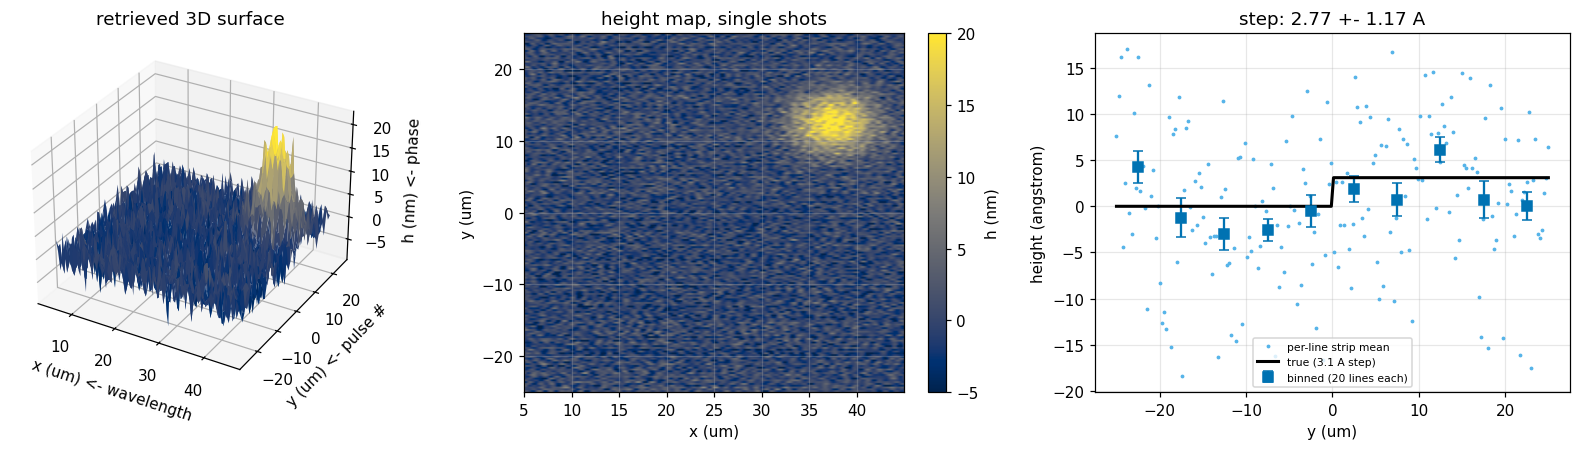

Figure 1. Left: the retrieved surface in 3D (cividis color = height); the 20 nm bump stands out above the noise. Middle: the same single-shot map from above (color -5..20 nm): the bump is clear, but the 3.1 A step along y = 0 is invisible, because one pixel is ~20 A noisy. Right: averaging is what reveals it: light-blue dots are per-pulse means over a strip of x, dark-blue squares are 20-pulse bins with standard errors, black is the true profile. All 200 pulses together give 2.77 +- 1.17 A against 3.10 A.
per-pixel height noise (central 80% of band): 22.5 A rms; phase-equivalent 0.018 rad at 1550 nm


In [2]:
scan = c.steam3d_scan(n_lines=200)
x, y, H, R = scan['x'], scan['y'], scan['H'], scan['R']
n = R.shape[1]
core = slice(n // 10, -n // 10)
est, se = c.step_estimate(scan)
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(15, 4.2))
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
Xg, Yg = np.meshgrid(x[core][::8]*1e6, y[::4]*1e6)
ax1.plot_surface(Xg, Yg, R[::4, core][:, ::8]*1e9, cmap='cividis', linewidth=0, antialiased=True)
ax1.set(xlabel='x (um) <- wavelength', ylabel='y (um) <- pulse #', zlabel='h (nm) <- phase', title='retrieved 3D surface')
ax2 = fig.add_subplot(1, 3, 2)
im = ax2.imshow(R[:, core]*1e9, origin='lower', aspect='auto', cmap='cividis', vmin=-5, vmax=20,
                extent=[x[core][0]*1e6, x[core][-1]*1e6, y[0]*1e6, y[-1]*1e6])
plt.colorbar(im, ax=ax2, label='h (nm)')
ax2.set(xlabel='x (um)', ylabel='y (um)', title='height map, single shots')
ax3 = fig.add_subplot(1, 3, 3)
cols = (x > 0.1*x.max()) & (x < 0.4*x.max())
line_mean = R[:, cols].mean(axis=1)
ax3.plot(y*1e6, line_mean*1e10, '.', ms=3, color=OI['sky'], label='per-line strip mean')
edges = np.linspace(y[0], y[-1], 11)
idx = np.digitize(y, edges[1:-1])
bm = np.array([line_mean[idx == b].mean() for b in range(10)])
bs = np.array([line_mean[idx == b].std(ddof=1)/np.sqrt((idx == b).sum()) for b in range(10)])
ax3.errorbar(0.5*(edges[1:] + edges[:-1])*1e6, bm*1e10, yerr=bs*1e10, fmt='s', color=OI['blue'], capsize=3, label='binned (20 lines each)')
ax3.plot(y*1e6, H[:, cols].mean(axis=1)*1e10, '-', color=OI['black'], lw=2, label='true (3.1 A step)')
ax3.set(xlabel='y (um)', ylabel='height (angstrom)', title=f'step: {est*1e10:.2f} +- {se*1e10:.2f} A'); ax3.legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Figure 1. Left: the retrieved surface in 3D (cividis color = height); the 20 nm bump stands out above the noise. '
      'Middle: the same single-shot map from above (color -5..20 nm): the bump is clear, but the 3.1 A step along y = 0 is '
      'invisible, because one pixel is ~20 A noisy. Right: averaging is what reveals it: light-blue dots are per-pulse means '
      'over a strip of x, dark-blue squares are 20-pulse bins with standard errors, black is the true profile. '
      f'All 200 pulses together give {est*1e10:.2f} +- {se*1e10:.2f} A against 3.10 A.')
err = (R - H)[:, core]
print(f'per-pixel height noise (central 80% of band): {err.std()*1e10:.1f} A rms; '
      f'phase-equivalent {err.std()*4*np.pi/1550e-9:.3f} rad at 1550 nm')

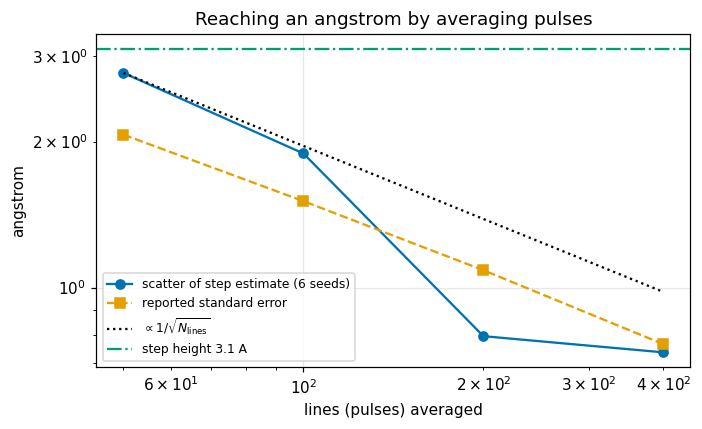

Figure 2. Uncertainty of the step-height estimate against the number of lines (pulses) used, log-log. Blue circles (solid): actual scatter over 6 noise seeds (itself uncertain, with only 6 samples); orange squares (dashed): the standard error the estimator reports; dotted black: 1/sqrt(N). When the uncertainty is near the dash-dot green line (the 3.1 A step), the step is barely resolved. A few hundred pulses, microseconds at a typical mode-locked pulse rate, bring it to ~1 A, roughly following 1/sqrt(N).


,lines,mean_step_A,scatter_A,mean_reported_se_A
0,50,2.297,2.771,2.067
1,100,2.663,1.891,1.508
2,200,3.506,0.794,1.086
3,400,3.236,0.735,0.765


In [3]:
rows = []
for nl in (50, 100, 200, 400):
    e = [c.step_estimate(c.steam3d_scan(n_lines=nl, seed=s)) for s in range(6)]
    vals = np.array([v for v, _ in e])
    rows.append(dict(lines=nl, mean_step_A=vals.mean()*1e10, scatter_A=vals.std(ddof=1)*1e10, mean_reported_se_A=np.mean([s_ for _, s_ in e])*1e10))
prec = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(prec.lines, prec.scatter_A, 'o-', color=OI['blue'], label='scatter of step estimate (6 seeds)')
ax.loglog(prec.lines, prec.mean_reported_se_A, 's--', color=OI['orange'], label='reported standard error')
ax.loglog(prec.lines, prec.scatter_A.iloc[0]*np.sqrt(prec.lines.iloc[0]/prec.lines), ':', color=OI['black'], label='$\\propto 1/\\sqrt{N_\\mathrm{lines}}$')
ax.axhline(3.1, color=OI['green'], ls='-.', label='step height 3.1 A')
ax.set(xlabel='lines (pulses) averaged', ylabel='angstrom', title='Reaching an angstrom by averaging pulses'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Uncertainty of the step-height estimate against the number of lines (pulses) used, log-log. Blue circles '
      '(solid): actual scatter over 6 noise seeds (itself uncertain, with only 6 samples); orange squares (dashed): the '
      'standard error the estimator reports; dotted black: 1/sqrt(N). When the uncertainty is near the dash-dot green line '
      '(the 3.1 A step), the step is barely resolved. A few hundred pulses, microseconds at a typical mode-locked pulse '
      'rate, bring it to ~1 A, roughly following 1/sqrt(N).')
prec.round(3)

## 2. The ångström limit: $h\to0$ on paper vs on a computer

SymPy does the calculus exactly: the difference quotient's limit, and the Taylor series of the 3-point second difference used in every finite-difference Schrödinger solver.

In [4]:
xs, hs_ = sp.symbols('x h', real=True)
f = sp.Function('f')
display(Math(r'\lim_{h\to0}\frac{(x+h)^2-x^2}{h} = ' + sp.latex(sp.limit(((xs+hs_)**2 - xs**2)/hs_, hs_, 0))))
g = sp.sin(xs)
sd = sp.series((g.subs(xs, xs+hs_) - 2*g + g.subs(xs, xs-hs_))/hs_**2, hs_, 0, 4).removeO()
display(Math(r'\frac{\sin(x+h)-2\sin x+\sin(x-h)}{h^2} = ' + sp.latex(sp.expand(sd)) + r' + O(h^4)'))
print('Truncation error is h^2/12 * f\'\'\'\'(x): it shrinks like h^2, on paper forever.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Truncation error is h^2/12 * f''''(x): it shrinks like h^2, on paper forever.


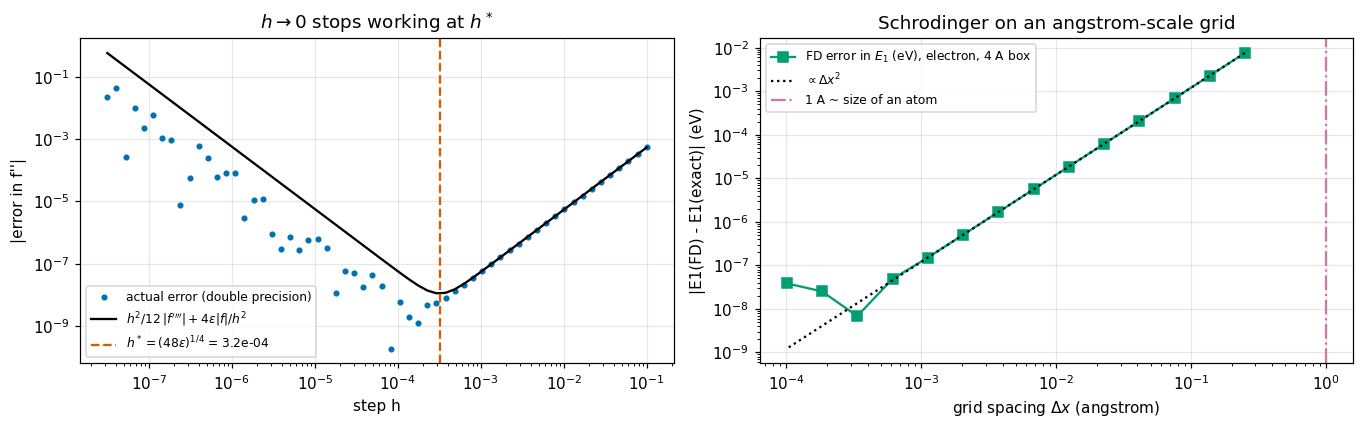

Figure 3. Left: error of the 3-point second derivative of sin(x) at x = 0.7 against step h (blue circles) with the truncation + round-off model (black; the round-off term is an upper envelope for the scattered points); the dashed red line marks the optimal step ~3e-4, below which the error grows again. Right: error of the finite-difference ground-state energy of an electron in a 4 A box against grid spacing in angstrom (green squares) with a dx^2 guide (dotted): it falls as dx^2 until about 3e-4 A, then stops improving, the same round-off floor now in a physical eigenvalue. The dash-dot purple line is 1 A: grids much finer than an atom are needed for accuracy, but the continuum model the grid approximates is itself only valid above roughly that scale.
Interferometric height precision lambda*dphi/(4 pi) at 1550 nm (angstrom); Si lattice 5.43 A, Si(111) step ~3.1 A, Bohr radius 0.53 A:


,phase_noise_rad,single_shot_A,avg_1e4_A
0,0.100,123.345081,1.233451
1,0.010,12.334508,0.123345
2,0.001,1.233451,0.012335


In [5]:
hs = np.logspace(-1, -7.5, 60)
err_fd = c.second_difference_error(hs)
# physical version: electron in a 4 A box, FD ground-state error vs grid spacing (in angstrom)
ngrid = np.unique(np.logspace(1.2, 4.6, 14).astype(int))
dxs = 4.0/(ngrid + 1)
E1_err = np.array([abs(c.lowest_levels(np.zeros(n_), 4.0/(n_+1), 1.0, 1)[0] - c.box_exact(1, 4.0, 1.0)) for n_ in ngrid])
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
ax[0].loglog(hs, err_fd, 'o', ms=3, color=OI['blue'], label='actual error (double precision)')
ax[0].loglog(hs, c.error_model(hs), '-', color=OI['black'], label='$h^2/12\\,|f\'\'\'\'| + 4\\epsilon|f|/h^2$')
ax[0].axvline(c.optimal_step(), color=OI['red'], ls='--', label=f'$h^*=(48\\epsilon)^{{1/4}}$ = {c.optimal_step():.1e}')
ax[0].set(xlabel='step h', ylabel='|error in f\'\'|', title='$h\\to0$ stops working at $h^*$'); ax[0].legend(fontsize=8)
ax[1].loglog(dxs, E1_err, 's-', color=OI['green'], label='FD error in $E_1$ (eV), electron, 4 A box')
ax[1].loglog(dxs, E1_err[0]*(dxs/dxs[0])**2, ':', color=OI['black'], label='$\\propto \\Delta x^2$')
ax[1].axvline(1.0, color=OI['purple'], ls='-.', label='1 A ~ size of an atom')
ax[1].set(xlabel='grid spacing $\\Delta x$ (angstrom)', ylabel='|E1(FD) - E1(exact)| (eV)', title='Schrodinger on an angstrom-scale grid'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Left: error of the 3-point second derivative of sin(x) at x = 0.7 against step h (blue circles) with the '
      'truncation + round-off model (black; the round-off term is an upper envelope for the scattered points); the dashed red '
      'line marks the optimal step ~3e-4, below which the error grows again. Right: error of the finite-difference ground-state '
      'energy of an electron in a 4 A box against grid spacing in angstrom (green squares) with a dx^2 guide (dotted): it falls '
      'as dx^2 until about 3e-4 A, then stops improving, the same round-off floor now in a physical eigenvalue. The dash-dot '
      'purple line is 1 A: grids much finer than an atom are needed for accuracy, but the continuum model the grid '
      'approximates is itself only valid above roughly that scale.')
lam = 1550e-9
tbl = pd.DataFrame([dict(phase_noise_rad=dp, single_shot_A=c.height_precision(lam, dp)*1e10,
                         avg_1e4_A=c.height_precision(lam, dp, 1e4)*1e10) for dp in (1e-1, 1e-2, 1e-3)])
print('Interferometric height precision lambda*dphi/(4 pi) at 1550 nm (angstrom); Si lattice 5.43 A, Si(111) step ~3.1 A, Bohr radius 0.53 A:')
tbl

## 3. Lean 4 + Mathlib: the calculus, checked

These are statements about **real numbers**, compiled against Mathlib in `~/lean/NavierStokesAndEuler` (narrow imports, so it takes seconds, not minutes):

* `limit_diff_quot_sq`: $\displaystyle\lim_{h\to0,\,h\ne0}\frac{(x+h)^2-x^2}{h}=2x$ as a genuine `Tendsto` statement on the punctured neighborhood $\mathcal N_{\ne}(0)$
* `diff_quot_sq`, `second_diff_quadratic`: the difference quotients are *exact* on quadratics (that's why FD solvers are exact for a harmonic potential's curvature)
* `box_ratio`, `qho_ratio`: $E_2/E_1=4$ (box) and $E_1/E_0=3$ (harmonic), the classifier's shape features
* `height_error_linear`: $\delta h=\lambda\,\delta\phi/4\pi$, the §1 precision law

The cell reports the actual compiler result. If `lake` or the Mathlib project is missing, it says the proofs were **not** verified.

In [6]:
LEAN_SRC = r'''
import Mathlib.Analysis.SpecialFunctions.Trigonometric.Basic
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Ring
import Mathlib.Tactic.NormNum

open Filter Topology

/-- The forward difference quotient of x^2 is exactly 2x + h. -/
theorem diff_quot_sq (x h : ℝ) (hh : h ≠ 0) : ((x + h) ^ 2 - x ^ 2) / h = 2 * x + h := by
  field_simp
  ring

/-- Calculus limit: the difference quotient of x^2 tends to 2x as h → 0 (h ≠ 0). -/
theorem limit_diff_quot_sq (x : ℝ) :
    Tendsto (fun h : ℝ => ((x + h) ^ 2 - x ^ 2) / h) (𝓝[≠] 0) (𝓝 (2 * x)) := by
  have hc : Tendsto (fun h : ℝ => 2 * x + h) (𝓝[≠] 0) (𝓝 (2 * x)) := by
    have : Tendsto (fun h : ℝ => 2 * x + h) (𝓝 0) (𝓝 (2 * x + 0)) :=
      (continuous_const.add continuous_id).tendsto 0
    simpa using this.mono_left nhdsWithin_le_nhds
  refine hc.congr' ?_
  filter_upwards [self_mem_nhdsWithin] with h hh
  exact (diff_quot_sq x h hh).symm

/-- The 3-point second difference (the finite-difference kinetic term) is exact on quadratics. -/
theorem second_diff_quadratic (a b c x h : ℝ) (hh : h ≠ 0) :
    ((a * (x + h) ^ 2 + b * (x + h) + c) - 2 * (a * x ^ 2 + b * x + c)
      + (a * (x - h) ^ 2 + b * (x - h) + c)) / h ^ 2 = 2 * a := by
  field_simp
  ring

/-- Infinite-well levels: E_n = n^2 E_1, so the ratio E_2 / E_1 = 4 (the classifier's shape feature). -/
theorem box_ratio (E1 : ℝ) (h1 : E1 ≠ 0) : (2 : ℝ) ^ 2 * E1 / ((1 : ℝ) ^ 2 * E1) = 4 := by
  field_simp
  norm_num

/-- Harmonic levels E_n = (n + 1/2) ħω: the ratio E_1 / E_0 = 3. -/
theorem qho_ratio (hw : ℝ) (h : hw ≠ 0) : ((1 : ℝ) + 1 / 2) * hw / (((0 : ℝ) + 1 / 2) * hw) = 3 := by
  field_simp
  norm_num

/-- Interferometric height: h = λ φ / (4π) is linear in φ, so a phase error δφ gives height error λ δφ / (4π). -/
theorem height_error_linear (lam phi dphi : ℝ) :
    lam * (phi + dphi) / (4 * Real.pi) - lam * phi / (4 * Real.pi) = lam * dphi / (4 * Real.pi) := by
  ring
'''

proj = pathlib.Path.home() / 'lean' / 'NavierStokesAndEuler'
lake = shutil.which('lake') or str(pathlib.Path.home() / '.elan' / 'bin' / 'lake.exe')
lean_file = pathlib.Path.cwd() / 'steam3d_qm_calculus.lean'
lean_file.write_text(LEAN_SRC.strip() + '\n', encoding='utf-8')
names = [l.split()[1] for l in LEAN_SRC.splitlines() if l.startswith('theorem ')]
if proj.exists() and pathlib.Path(lake).exists():
    t0 = time.perf_counter()
    r = subprocess.run([lake, 'env', 'lean', str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1200)
    log = (r.stdout + r.stderr).strip()
    lean_ok = r.returncode == 0 and 'sorry' not in log
    print(f'{lean_file.name}: exit code {r.returncode} in {time.perf_counter()-t0:.1f} s; theorems: {", ".join(names)}')
    print(log or 'no errors or warnings: every theorem above was checked by the Lean kernel against Mathlib')
else:
    lean_ok = False
    print('Mathlib project or lake not found: file written but NOT compiled, nothing verified')

steam3d_qm_calculus.lean: exit code 0 in 9.7 s; theorems: diff_quot_sq, limit_diff_quot_sq, second_diff_quadratic, box_ratio, qho_ratio, height_error_linear
no errors or warnings: every theorem above was checked by the Lean kernel against Mathlib


## 4. A particle classifier from 1D Schrödinger spectra

Units: Å and eV, with $\hbar^2/2m_e=3.810$ eV·Å². Devices have **nominal** sizes (box $L=4$ Å; harmonic $k=10$ eV/Å²; V-shaped well $V=F|x|$, $F=5$ eV/Å) with fabrication **jitter**. The level readout has 1% noise. The finite-difference spectra are checked against the closed forms first:

| potential | $E_n$ | ratios $E_2/E_1,E_3/E_1,E_4/E_1$ | mass scaling |
|---|---|---|---|
| box | $\frac{\hbar^2}{2m}\left(\frac{n\pi}{L}\right)^2$ | 4, 9, 16 | $m^{-1}$ |
| harmonic | $(n+\tfrac12)\hbar\sqrt{k/m}$ | 3, 5, 7 | $m^{-1/2}$ |
| linear $F\lvert x\rvert$ | $\lvert a_n\rvert\left(\frac{\hbar^2F^2}{2m}\right)^{1/3}$, Airy zeros | 2.295, 3.188, 4.012 | $m^{-1/3}$ |

In [7]:
rows = []
for p, mr in c.MASS.items():
    for pot, exact in [('box', c.box_exact([1, 2, 3, 4], 4.0, mr)), ('harmonic', c.harmonic_exact([0, 1, 2, 3], 10.0, mr)),
                       ('linear', c.linear_exact(4, 5.0, mr))]:
        E = c.spectrum(p, pot)
        f_ = c.features(E)
        rows.append(dict(particle=p, potential=pot, E1_eV=E[0], max_rel_err_vs_exact=np.max(np.abs(E/exact - 1)),
                         E2_E1=f_[1], E3_E1=f_[2], E4_E1=f_[3]))
spec = pd.DataFrame(rows)
assert spec.max_rel_err_vs_exact.max() < 1e-4
spec

,particle,potential,E1_eV,max_rel_err_vs_exact,E2_E1,E3_E1,E4_E1
0,electron,box,2.350187,0.000009,3.999993,8.999959,15.999863
1,electron,harmonic,4.364544,0.000062,2.999965,4.999861,6.999687
2,electron,linear,4.652733,0.000027,2.294936,3.188205,4.012421
3,muon,box,0.011366,0.000009,3.999993,8.999959,15.999863
4,muon,harmonic,0.303527,0.000062,2.999965,4.999861,6.999687
5,muon,linear,0.786829,0.000027,2.294936,3.188205,4.012421
6,proton,box,0.001280,0.000009,3.999993,8.999959,15.999863
7,proton,harmonic,0.101856,0.000062,2.999965,4.999861,6.999687
8,proton,linear,0.379961,0.000027,2.294936,3.188205,4.012421
9,deuteron,box,0.000640,0.000009,3.999993,8.999959,15.999863


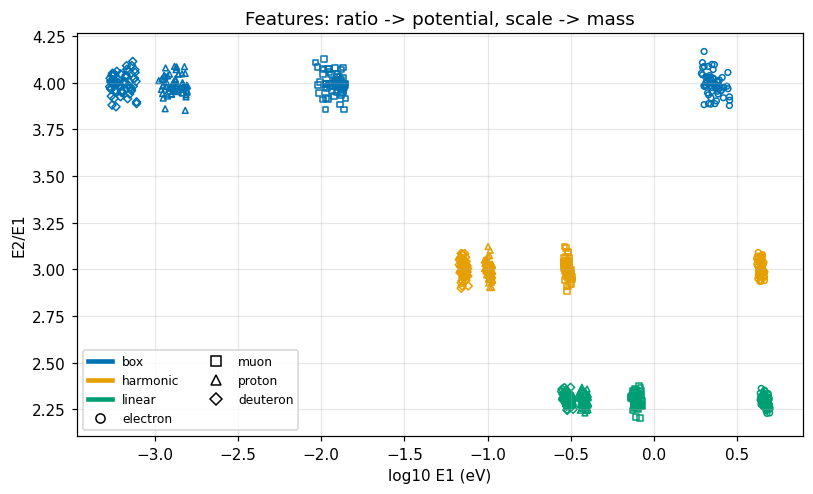

Figure 4. Each point is one simulated device: log10 of the ground energy (x) against the E2/E1 ratio (y). Color = potential (blue box near 4, orange harmonic at 3, green V-well near 2.3); marker = particle (circle electron, square muon, triangle proton, diamond deuteron). Rows separate the potential; positions along a row separate the mass. Proton and deuteron (mass ratio 2) sit closest, worst in the V-well, where energy scales only as m^-1/3.
test accuracy at 10% geometry jitter: 1.000


In [8]:
X, y = c.make_dataset(60, jitter=0.10)
model, Xte, yte, acc10 = c.train_classifier(X, y)
part = np.array([s_.split('|')[0] for s_ in y]); pot = np.array([s_.split('|')[1] for s_ in y])
colors = {'box': OI['blue'], 'harmonic': OI['orange'], 'linear': OI['green']}
markers = {'electron': 'o', 'muon': 's', 'proton': '^', 'deuteron': 'D'}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for p in c.MASS:
    for q in c.POTENTIALS:
        sel = (part == p) & (pot == q)
        ax.scatter(X[sel, 0], X[sel, 1], s=14, marker=markers[p], facecolors='none', edgecolors=colors[q],
                   label=f'{p} / {q}' if p == 'electron' or q == 'box' else None)
ax.set(xlabel=c.FEATURE_NAMES[0], ylabel=c.FEATURE_NAMES[1], title='Features: ratio -> potential, scale -> mass')
handles = [plt.Line2D([], [], color=colors[q], lw=3, label=q) for q in c.POTENTIALS] + \
          [plt.Line2D([], [], color='k', marker=markers[p], ls='', mfc='none', label=p) for p in c.MASS]
ax.legend(handles=handles, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
print('Figure 4. Each point is one simulated device: log10 of the ground energy (x) against the E2/E1 ratio (y). Color = '
      'potential (blue box near 4, orange harmonic at 3, green V-well near 2.3); marker = particle (circle electron, square '
      'muon, triangle proton, diamond deuteron). Rows separate the potential; positions along a row separate the mass. Proton '
      'and deuteron (mass ratio 2) sit closest, worst in the V-well, where energy scales only as m^-1/3.')
print(f'test accuracy at 10% geometry jitter: {acc10:.3f}')

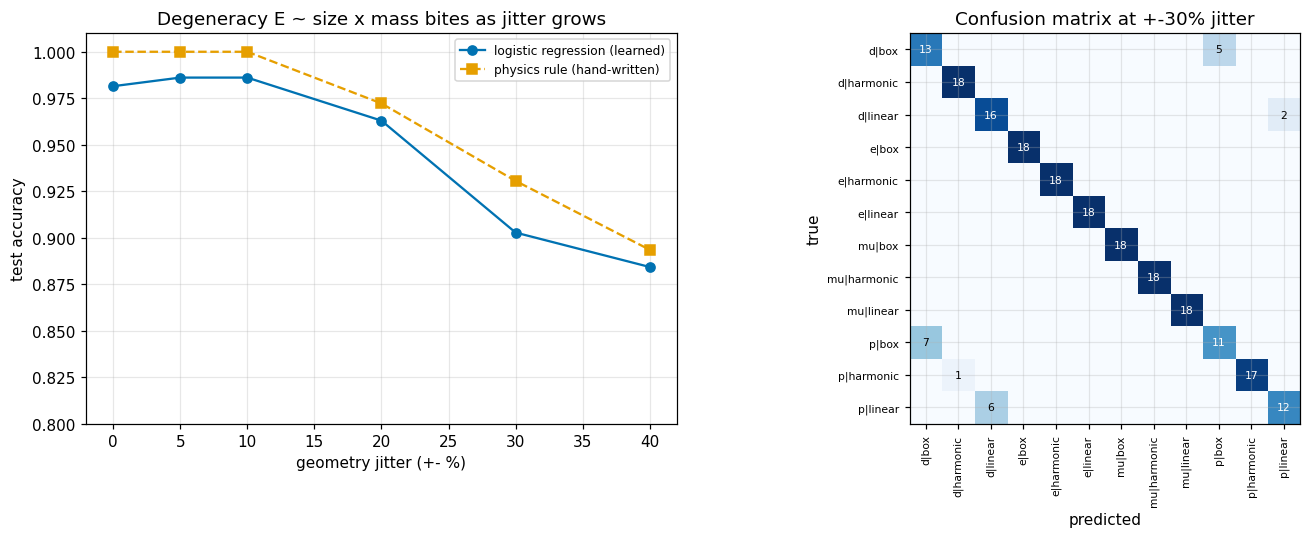

Figure 5. Left: test accuracy against device jitter for the learned classifier (blue circles) and a hand-written physics rule (orange squares). The rule is perfect up to 10% jitter; logistic regression peaks at 0.986 (a linear model in these features cannot place every boundary exactly). Both lose accuracy once size variation can fake a mass change. Right: confusion matrix at 30% jitter (rows true, columns predicted; e/mu/p/d = electron/muon/proton/deuteron). Errors are mass mix-ups within the same potential, mostly proton/deuteron; potential confusions: 0, because the level ratios do not depend on size or mass.


,jitter,logistic_regression,physics_rule
0,0.00,0.981481,1.000000
1,0.05,0.986111,1.000000
2,0.10,0.986111,1.000000
3,0.20,0.962963,0.972222
4,0.30,0.902778,0.930556
5,0.40,0.884259,0.893519


In [9]:
from sklearn.metrics import confusion_matrix
jit_rows = []
for jit in (0.0, 0.05, 0.10, 0.20, 0.30, 0.40):
    Xj, yj = c.make_dataset(60, jitter=jit, seed=1)
    m_, Xt, yt, a = c.train_classifier(Xj, yj)
    rule = np.mean([c.physics_rule(r_) == l_ for r_, l_ in zip(Xt, yt)])
    jit_rows.append(dict(jitter=jit, logistic_regression=a, physics_rule=rule))
    if jit == 0.30:
        labels = sorted(set(yj)); cm = confusion_matrix(yt, m_.predict(Xt), labels=labels)
jt = pd.DataFrame(jit_rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax[0].plot(jt.jitter*100, jt.logistic_regression, 'o-', color=OI['blue'], label='logistic regression (learned)')
ax[0].plot(jt.jitter*100, jt.physics_rule, 's--', color=OI['orange'], label='physics rule (hand-written)')
ax[0].set(xlabel='geometry jitter (+- %)', ylabel='test accuracy', ylim=(0.8, 1.01), title='Degeneracy E ~ size x mass bites as jitter grows'); ax[0].legend(fontsize=8)
im = ax[1].imshow(cm, cmap='Blues')
short = [l.replace('electron', 'e').replace('muon', 'mu').replace('proton', 'p').replace('deuteron', 'd') for l in labels]
ax[1].set_xticks(range(len(labels))); ax[1].set_xticklabels(short, rotation=90, fontsize=7)
ax[1].set_yticks(range(len(labels))); ax[1].set_yticklabels(short, fontsize=7)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax[1].text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cm[i, j] > cm.max()/2 else 'black')
ax[1].set(xlabel='predicted', ylabel='true', title='Confusion matrix at +-30% jitter')
plt.tight_layout(); plt.show()
pot_t = np.array([l.split('|')[1] for l in labels])
pot_confusions = int(sum(cm[i, j] for i in range(len(labels)) for j in range(len(labels)) if pot_t[i] != pot_t[j]))
print('Figure 5. Left: test accuracy against device jitter for the learned classifier (blue circles) and a hand-written physics '
      f'rule (orange squares). The rule is perfect up to 10% jitter; logistic regression peaks at {jt.logistic_regression.max():.3f} '
      '(a linear model in these features cannot place every boundary exactly). Both lose accuracy once size variation can fake '
      'a mass change. Right: confusion matrix at 30% jitter (rows true, columns predicted; e/mu/p/d = electron/muon/proton/'
      f'deuteron). Errors are mass mix-ups within the same potential, mostly proton/deuteron; potential confusions: '
      f'{pot_confusions}, because the level ratios do not depend on size or mass.')
jt

## 5. How this connects back to STEAM

| | time-stretch cell classification [2] | this notebook |
|---|---|---|
| forward model | time-stretch quantitative phase imaging: optical path ($\propto$ height × index) and loss per pixel | 1D Schrödinger equation, finite differences |
| features | size, optical phase/thickness, attenuation, … | $\log E_1$, $E_2/E_1$, $E_3/E_1$, $E_4/E_1$ |
| classifier | deep network / regression | logistic regression vs a physics rule |
| what limits accuracy | cells that differ in ways the features can't see | the degeneracy $E\propto f(\text{size})/m^{p}$ |
| 3D | height from phase, as in §1 | |

The design lesson carries over: **pick features that the nuisance variables can't fake.** Level ratios are immune to size and mass, so the potential is never confused. The absolute scale is not immune, so the mass is.

**References** (from memory; verify before citing)
[1] K. Goda, K. K. Tsia, and B. Jalali, "Serial time-encoded amplified imaging for real-time observation of fast dynamic phenomena," *Nature*, vol. 458, pp. 1145–1149, 2009.
[2] C. L. Chen, A. Mahjoubfar, L.-C. Tai, I. K. Blaby, A. Huang, K. R. Niazi, and B. Jalali, "Deep learning in label-free cell classification," *Sci. Rep.*, vol. 6, Art. no. 21471, 2016.
[3] M. Takeda, H. Ina, and S. Kobayashi, "Fourier-transform method of fringe-pattern analysis for computer-based topography and interferometry," *J. Opt. Soc. Am.*, vol. 72, no. 1, pp. 156–160, 1982.
[4] O. Vallée and M. Soares, *Airy Functions and Applications to Physics*. London, U.K.: Imperial College Press, 2004.
[5] The mathlib Community, "The Lean mathematical library," in *Proc. 9th ACM SIGPLAN Int. Conf. Certified Programs and Proofs (CPP)*, 2020, pp. 367–381.

**Limitations.**
- The 3D STEAM simulation idealizes the optics. Spectral encoding is perfectly linear, the dispersive Fourier transform is ideal (no finite stretch or detector bandwidth), and each line is referenced to a known flat strip. Fourier fringe analysis also leaves a slowly decaying ripple near the band edges; apodization would reduce it.
- The classifier uses Dirichlet-walled 1D toy devices and 1% level noise.
- The Lean proofs cover quadratics, the limit of one difference quotient, and level-ratio algebra, not the full finite-difference convergence theorem.